Customer Spending Prediction

In [122]:
#import necessary libraries
import pandas as  pd 
import seaborn as  sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error
from sklearn.linear_model import LinearRegression,Ridge,Lasso 
from sklearn.ensemble import RandomForestRegressor 
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


In [123]:
df = pd.read_csv(r'C:\Users\SHAHID MANSURI\Desktop\Customer spending prediction\datasets\ShopSmart_data.csv')


### EDA


In [124]:
df.head()

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent
0,46,620358.0,11.0,8,Silver,Beauty,Tier 1,Yes,16924.36
1,27,560886.0,13.0,7,Silver,Fashion,Tier 1,No,16467.52
2,52,866655.0,11.0,9,Bronze,Home,Tier 1,No,19224.61
3,55,816016.0,17.0,9,Silver,Home,Tier 2,Yes,20219.63
4,18,355468.0,14.0,0,Bronze,Home,Tier 3,Yes,7345.37


In [125]:
df.tail()

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent
1995,47,557297.0,5.0,6,Gold,Home,Tier 1,No,17423.64
1996,46,1027242.0,11.0,12,Bronze,Fashion,Tier 3,No,19939.64
1997,40,677690.0,15.0,4,Bronze,Fashion,Tier 3,Yes,13397.79
1998,34,565410.0,11.0,8,Silver,Electronics,Tier 3,Yes,17682.11
1999,65,397581.0,6.0,8,Bronze,Fashion,Tier 3,No,11165.42


In [126]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 2000 non-null   int64  
 1   Annual_Income       1984 non-null   float64
 2   Website_Visits      1984 non-null   float64
 3   Previous_Purchases  2000 non-null   int64  
 4   Membership_Type     1984 non-null   str    
 5   Preferred_Category  1984 non-null   str    
 6   City_Tier           2000 non-null   str    
 7   Discount_Used       2000 non-null   str    
 8   Amount_Spent        2000 non-null   float64
dtypes: float64(3), int64(2), str(4)
memory usage: 182.7 KB


In [127]:
df.isnull().sum()

Age                    0
Annual_Income         16
Website_Visits        16
Previous_Purchases     0
Membership_Type       16
Preferred_Category    16
City_Tier              0
Discount_Used          0
Amount_Spent           0
dtype: int64

In [128]:
#handling null values
avg_income=round(df['Annual_Income'].mean())
avg_web_visits=round(df['Website_Visits'].mean())
freq_category = df['Preferred_Category'].mode()[0]
freq_membership = df['Membership_Type'].mode()[0]

df['Annual_Income'] = df['Annual_Income'].fillna(avg_income)
df['Website_Visits'] = df['Website_Visits'].fillna(avg_web_visits)
df['Preferred_Category'] = df['Preferred_Category'].fillna(freq_category)
df['Membership_Type'] = df['Membership_Type'].fillna(freq_membership)


In [129]:
df.isnull().sum()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 2000 non-null   int64  
 1   Annual_Income       2000 non-null   float64
 2   Website_Visits      2000 non-null   float64
 3   Previous_Purchases  2000 non-null   int64  
 4   Membership_Type     2000 non-null   str    
 5   Preferred_Category  2000 non-null   str    
 6   City_Tier           2000 non-null   str    
 7   Discount_Used       2000 non-null   str    
 8   Amount_Spent        2000 non-null   float64
dtypes: float64(3), int64(2), str(4)
memory usage: 182.4 KB


In [130]:
#check Duplicate Rows
df[df.duplicated()]

,Age,Annual_Income,Website_Visits,Previous_Purchases,Membership_Type,Preferred_Category,City_Tier,Discount_Used,Amount_Spent


In [131]:
#summary of dataset
df.describe()

,Age,Annual_Income,Website_Visits,Previous_Purchases,Amount_Spent
count,2000.000000,2.000000e+03,2000.00000,2000.0000,2000.000000
mean,40.917500,7.525418e+05,9.95650,6.9655,17505.982405
std,12.780116,2.728578e+05,3.09134,2.6235,3866.061235
min,18.000000,1.800000e+05,2.00000,0.0000,6875.410000
25%,32.000000,5.605328e+05,8.00000,5.0000,14864.417500
50%,41.000000,7.520560e+05,10.00000,7.0000,17381.955000
75%,50.000000,9.346820e+05,12.00000,9.0000,19927.317500
max,65.000000,1.604606e+06,20.00000,16.0000,35371.200000


In [132]:
#check numaric columns 
num_cols=[]
for col in df.columns:
    if df[col].dtype != "str":
        num_cols.append(col)

df[num_cols]

,Age,Annual_Income,Website_Visits,Previous_Purchases,Amount_Spent
0,46,620358.0,11.0,8,16924.36
1,27,560886.0,13.0,7,16467.52
2,52,866655.0,11.0,9,19224.61
3,55,816016.0,17.0,9,20219.63
4,18,355468.0,14.0,0,7345.37
...,...,...,...,...,...
1995,47,557297.0,5.0,6,17423.64
1996,46,1027242.0,11.0,12,19939.64
1997,40,677690.0,15.0,4,13397.79
1998,34,565410.0,11.0,8,17682.11


In [133]:
#check object columns 
cat_cols=[]
for col in df.columns:
    if df[col].dtype == "str":
        cat_cols.append(col)

df[cat_cols]

,Membership_Type,Preferred_Category,City_Tier,Discount_Used
0,Silver,Beauty,Tier 1,Yes
1,Silver,Fashion,Tier 1,No
2,Bronze,Home,Tier 1,No
3,Silver,Home,Tier 2,Yes
4,Bronze,Home,Tier 3,Yes
...,...,...,...,...
1995,Gold,Home,Tier 1,No
1996,Bronze,Fashion,Tier 3,No
1997,Bronze,Fashion,Tier 3,Yes
1998,Silver,Electronics,Tier 3,Yes


<Axes: xlabel='Preferred_Category', ylabel='Amount_Spent'>

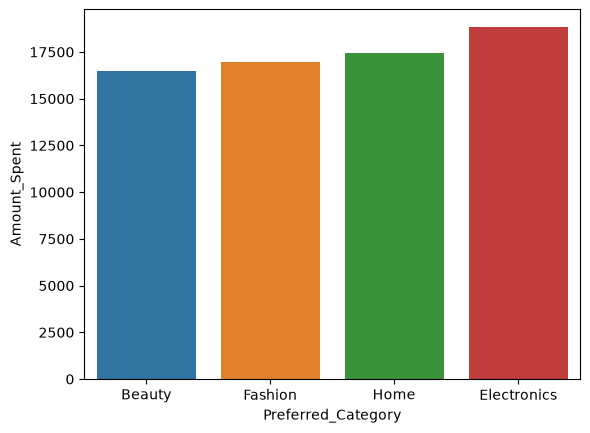

In [134]:
sns.barplot(x="Preferred_Category",y="Amount_Spent",data=df,errorbar=None,hue="Preferred_Category")

<Axes: xlabel='Age', ylabel='Amount_Spent'>

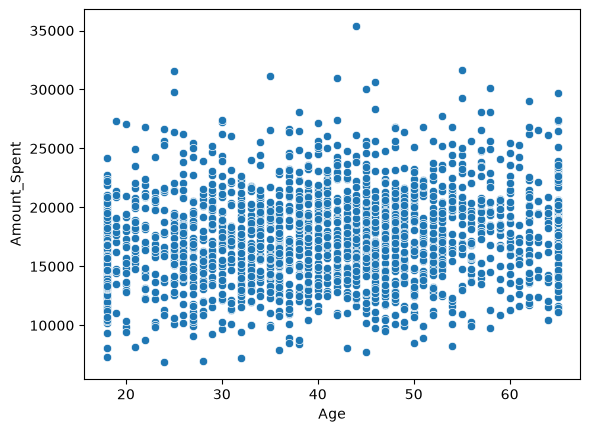

In [135]:
sns.scatterplot(x="Age",y="Amount_Spent",data=df)

Most of the customers are spending in between 10000 to 25000 Rs.

<Axes: xlabel='Website_Visits', ylabel='Count'>

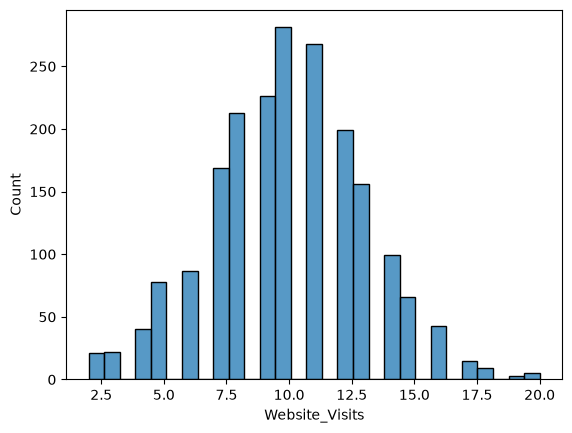

In [136]:
sns.histplot(x="Website_Visits",data=df)

Most of the customer visiting the website in between 7  to 13 time

<Axes: xlabel='Membership_Type', ylabel='Amount_Spent'>

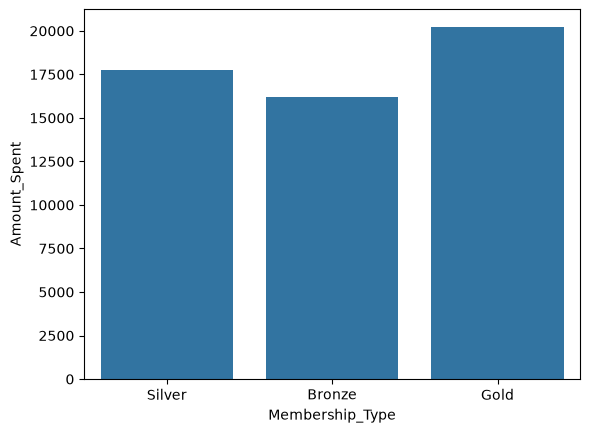

In [137]:
sns.barplot(x="Membership_Type",y='Amount_Spent',data=df,errorbar=None)

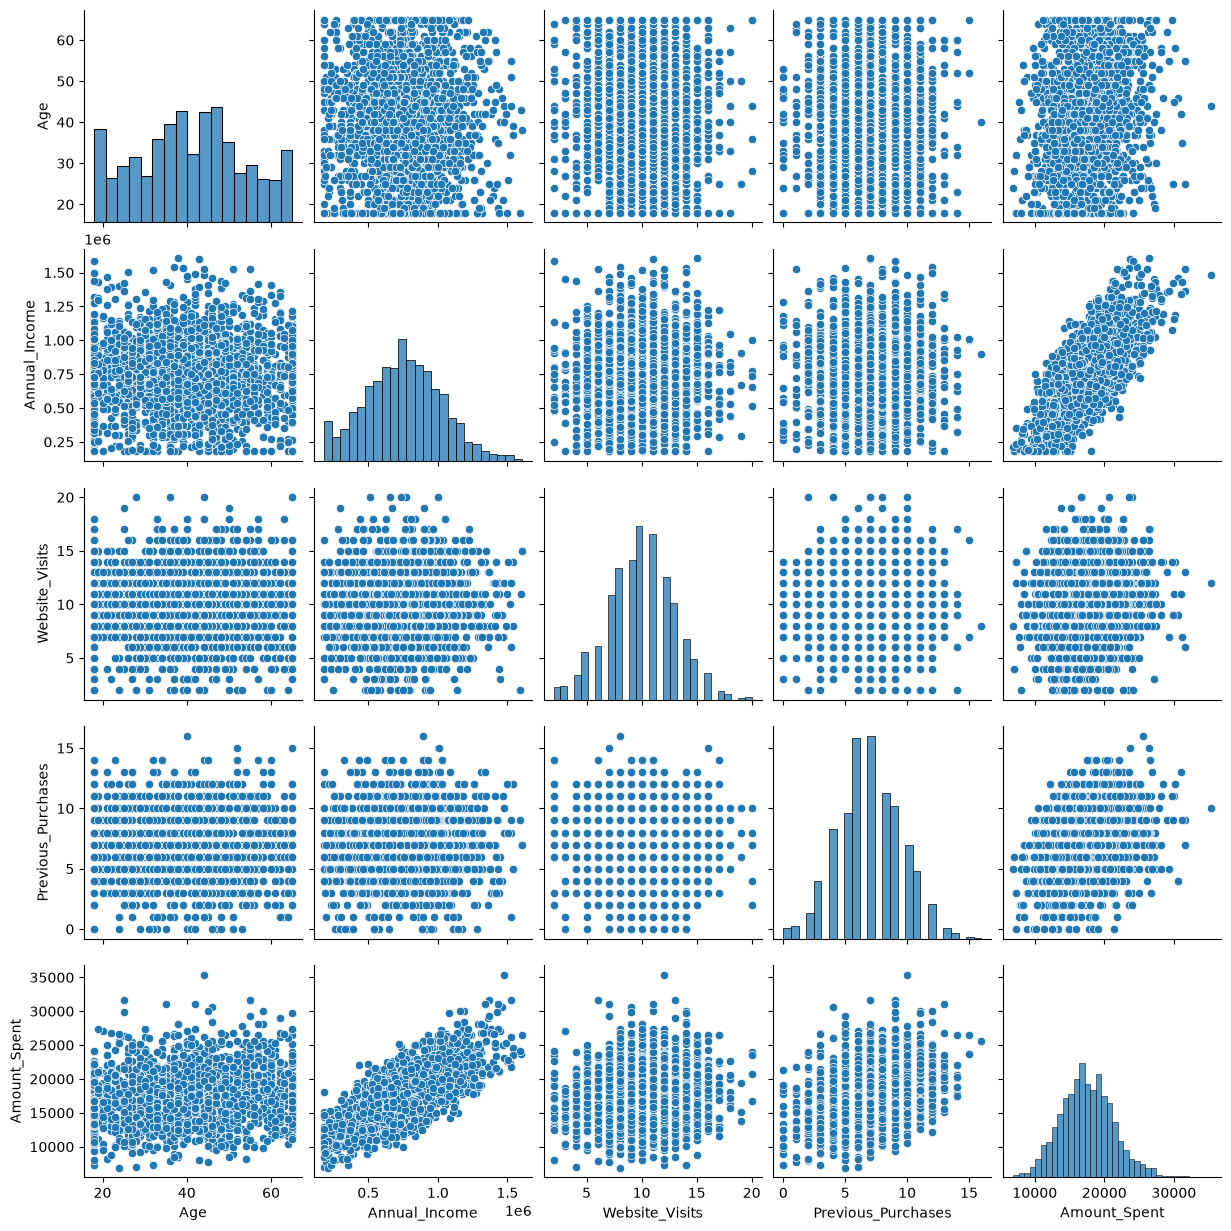

In [138]:
#find correlation beetween column
# corr =df[num_cols].corr()
# sns.heatmap(corr,annot=True)
sns.pairplot(df)

Model Pipeline

In [139]:
#devide the data into input and output columns
X =df.drop('Amount_Spent',axis=1)
y=df['Amount_Spent']

In [140]:
Xtrain,Xtest,ytrain,ytest = train_test_split(X,y,test_size=0.3,random_state=42)


In [141]:
num_cols = Xtrain.select_dtypes(include="number").columns
cat_cols = Xtrain.select_dtypes(include="str").columns


In [142]:
model  = {"Liner Reggression " :Pipeline([  ("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                               ("scaler",StandardScaler(),num_cols)])),
                                            ("model",LinearRegression())]),
        "Ridge" :Pipeline([  ("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                               ("scaler",StandardScaler(),num_cols)])),
                                            ("model",Ridge(alpha=50))]),
            "Lasso " :Pipeline([  ("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                               ("scaler",StandardScaler(),num_cols)])),
                                            ("model",Lasso(alpha=100))]),
       "Decision tree" :Pipeline([  ("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                               ("scaler",StandardScaler(),num_cols)])),
                                            ("model",DecisionTreeRegressor(max_depth=10))]),
           "Random Forest" :Pipeline([  ("preprocessor",ColumnTransformer([("encoder",OneHotEncoder(),cat_cols),
                                                                               ("scaler",StandardScaler(),num_cols)])),
                                            ("model",RandomForestRegressor(n_estimators=100,max_depth=7,random_state=42))])
}


In [143]:
#Multi model training
model_perf={}

for model_name,pipeline in model.items():
    pipeline.fit(Xtrain,ytrain)
    ypred =pipeline.predict(Xtest)
    r2 =r2_score(ytest,ypred)
    mae =mean_absolute_error(ytest,ypred)
    mse =mean_squared_error(ytest,ypred)
    model_perf[model_name]  = {"R2":r2,"MSE":mse, "MAE":mae}

In [144]:
perf_df = pd.DataFrame(model_perf)
perf_df

,Liner Reggression,Ridge,Lasso,Decision tree,Random Forest
R2,0.948411,0.945508,9.219361e-01,7.723925e-01,8.558681e-01
MSE,748773.147905,790913.976980,1.133044e+06,3.303567e+06,2.091976e+06
MAE,617.571794,637.820955,8.214268e+02,1.417310e+03,1.132605e+03


In [146]:
best_model_data = max(model_perf.items(),key=lambda d:d[1]["R2"])
best_model_name  =best_model_data[0]
print(best_model_data)
best_model_pipeline  = model[best_model_name]

('Liner Reggression ', {'R2': 0.9484114030748212, 'MSE': 748773.1479047132, 'MAE': 617.5717936465322})


In [150]:
best_model_pipeline.predict(Xtest)

array([14300.70821746, 18868.39803924, 21971.15353009, 18737.94405993,
       16436.42119351, 17202.76154403, 15377.20150439, 21325.65246883,
       15865.06206069, 17277.42577381, 13888.14976577, 16093.40582274,
       13677.31782594, 17415.88257148, 15663.74260122, 10125.80259628,
       18838.29969687, 22163.78213348, 15654.46952326, 15196.37727142,
       19751.23780891, 18291.28036664, 17704.59403663, 17981.41677218,
       15263.22950359, 20738.0649449 , 17682.11238067, 17959.57952301,
       18354.74055789, 12602.2609369 , 15750.38863006, 13783.45246416,
       28358.7905974 , 17406.7892587 , 16593.83373872, 15833.40324013,
       16347.84898046, 18796.29947389, 14010.96415369, 20601.09709545,
       16641.1926763 ,  9845.65563136, 16165.36509138, 23541.32722822,
       19370.07059054, 20790.03422243, 16708.21877095, 17124.57748792,
       19334.39449236, 23177.65065194, 18636.64185262, 12833.74443307,
        7984.53431687, 24789.60762942, 20556.17864924, 13783.75242183,
      

In [151]:
import pickle
with open(r"C:\Users\SHAHID MANSURI\Desktop\Customer spending prediction\best_model\best_model.pkl","wb") as file:
    pickle.dump(best_model_pipeline,file)

In [153]:
df.to_csv(r'C:\Users\SHAHID MANSURI\Desktop\Customer spending prediction\datasets\data_cleaned.csv')

In [ ]:
Xtrain.columns

Index(['Age', 'Annual_Income', 'Website_Visits', 'Previous_Purchases',
       'Membership_Type', 'Preferred_Category', 'City_Tier', 'Discount_Used'],
      dtype='str')

In [155]:
df['Annual_Income']

0        620358.0
1        560886.0
2        866655.0
3        816016.0
4        355468.0
          ...    
1995     557297.0
1996    1027242.0
1997     677690.0
1998     565410.0
1999     397581.0
Name: Annual_Income, Length: 2000, dtype: float64